## Import Libraries

In [24]:
import pandas as pd
import numpy as np
from math import sin, cos, pi
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

## Data preparation

In [25]:
# Read the Excel file into a DataFrame - data from SQL query
df_sql = pd.read_excel("C:/Users/9000639/Documents/CQ_SerieTemporal/temporal-series-analysis/data/SQL_data.xlsx")
for column in ["ger200k_data_contagem", "ger400k_data_contagem", "ea_data1_contagem", "ger_v_data_contagem"]:
    df_sql[column] = pd.to_datetime(df_sql[column], errors='coerce', dayfirst=True)
df_sql.head()

C:\Users\9000639\AppData\Local\Temp\ipykernel_15976\1466779563.py:4: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_sql[column] = pd.to_datetime(df_sql[column], errors='coerce', dayfirst=True)
C:\Users\9000639\AppData\Local\Temp\ipykernel_15976\1466779563.py:4: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_sql[column] = pd.to_datetime(df_sql[column], errors='coerce', dayfirst=True)


,sample_category,sample_type,ger200k_data_contagem,ger400k_data_contagem,ea_data1_contagem,ger_v_data_contagem
0,Comercial,Reanálise de Sobra,NaT,2025-03-26 15:00:00,2025-02-04 15:59:08,NaT
1,Básica,Final Gen2,NaT,NaT,NaT,NaT
2,Comercial,Bulk,NaT,NaT,NaT,NaT
3,Comercial,Bulk Peneiras,2025-03-20 15:00:00,NaT,NaT,NaT
4,Comercial,Bulk Peneiras,2025-03-20 15:00:00,NaT,NaT,NaT


In [26]:
# Read the Excel file into a DataFrame - data from paper sample
df_paper = pd.read_excel("C:/Users/9000639/Documents/CQ_SerieTemporal/temporal-series-analysis/data/Quantidade_papel_amostra.xlsx")
df_paper.head()

,sample_category,sample_type,paper_value
0,Comercial,Reanálise de Sobra,24
1,Comercial,Lote Final,24
2,Comercial,Bulk Peneiras,12
3,Comercial,Devolução,24
4,Comercial,Bulk,12


In [27]:
# Merge the two DataFrames
df_ = df_sql.merge(df_paper, how='left', on=['sample_category', 'sample_type'], validate='m:1')
df_

,sample_category,sample_type,ger200k_data_contagem,ger400k_data_contagem,ea_data1_contagem,ger_v_data_contagem,paper_value
0,Comercial,Reanálise de Sobra,NaT,2025-03-26 15:00:00,2025-02-04 15:59:08,NaT,24.0
1,Básica,Final Gen2,NaT,NaT,NaT,NaT,12.0
2,Comercial,Bulk,NaT,NaT,NaT,NaT,12.0
3,Comercial,Bulk Peneiras,2025-03-20 15:00:00,NaT,NaT,NaT,12.0
4,Comercial,Bulk Peneiras,2025-03-20 15:00:00,NaT,NaT,NaT,12.0
...,...,...,...,...,...,...,...
196015,Comercial,Reanálise de Sobra,NaT,2024-08-27 15:00:00,2024-10-07 14:11:26,NaT,24.0
196016,Comercial,Reanálise de Sobra,NaT,2024-10-02 15:00:00,2024-10-07 14:15:45,NaT,24.0
196017,Comercial,Reanálise de Sobra,NaT,2024-10-02 15:00:00,2024-10-07 14:20:09,NaT,24.0
196018,Comercial,Reanálise de Sobra,NaT,2024-10-02 15:00:00,2024-10-07 14:23:30,NaT,24.0


In [28]:
df_date = df_.melt(id_vars=['sample_category', 'sample_type', 'paper_value'],
                  value_vars=['ger200k_data_contagem', 'ger400k_data_contagem', 'ea_data1_contagem', 'ger_v_data_contagem'],
                  var_name='data_type', value_name='date')
df_date = df_date.dropna(subset=['date'])
df_date['date'] = df_date['date'].dt.normalize()  # Normalize the date to remove time component
df_date.head()

,sample_category,sample_type,paper_value,data_type,date
3,Comercial,Bulk Peneiras,12.0,ger200k_data_contagem,2025-03-20
4,Comercial,Bulk Peneiras,12.0,ger200k_data_contagem,2025-03-20
8,Comercial,Bulk Peneiras,12.0,ger200k_data_contagem,2025-03-20
16,Comercial,Bulk Peneiras,12.0,ger200k_data_contagem,2025-03-20
20,Comercial,Bulk Peneiras,12.0,ger200k_data_contagem,2025-03-20


In [29]:
df_daily = (
    df_date.groupby("date", as_index=False)["paper_value"].sum()
    .rename(columns={"paper_value": "daily_paper"})
    .sort_values("date")
    .reset_index(drop=True)
)
df_daily = df_daily.sort_values("date").drop_duplicates(subset=["date"], keep="first").reset_index(drop=True)
df_daily = df_daily[df_daily["date"].dt.year>2022]
df_daily

,date,daily_paper
195,2023-01-02,3168.0
196,2023-01-03,1380.0
197,2023-01-04,756.0
198,2023-01-05,2148.0
199,2023-01-06,2964.0
...,...,...
1287,2026-12-03,288.0
1288,2026-12-05,216.0
1289,2026-12-06,2256.0
1290,2026-12-08,3996.0


In [30]:
df_daily.to_csv("C:/Users/9000639/Documents/CQ_SerieTemporal/temporal-series-analysis/data/daily_paper_data.csv", index=False)

In [31]:
df_daily = pd.read_csv("C:/Users/9000639/Documents/CQ_SerieTemporal/temporal-series-analysis/data/daily_paper_data.csv", parse_dates=["date"])
df_daily.head()

,date,daily_paper
0,2023-01-02,3168.0
1,2023-01-03,1380.0
2,2023-01-04,756.0
3,2023-01-05,2148.0
4,2023-01-06,2964.0


## Data analysis

In [32]:
# Data correlation analysis
# ADF Test
adf_result = adfuller(df_daily["daily_paper"].dropna())
p_value = adf_result[1]
print(f"Estatística ADF: {adf_result[0]:.4f}")
print(f"p-valor: {p_value:.6f}")

Estatística ADF: -5.1593
p-valor: 0.000011


C:\Users\9000639\AppData\Local\Temp\ipykernel_15976\789065440.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df_daily["daily_paper"].dropna())


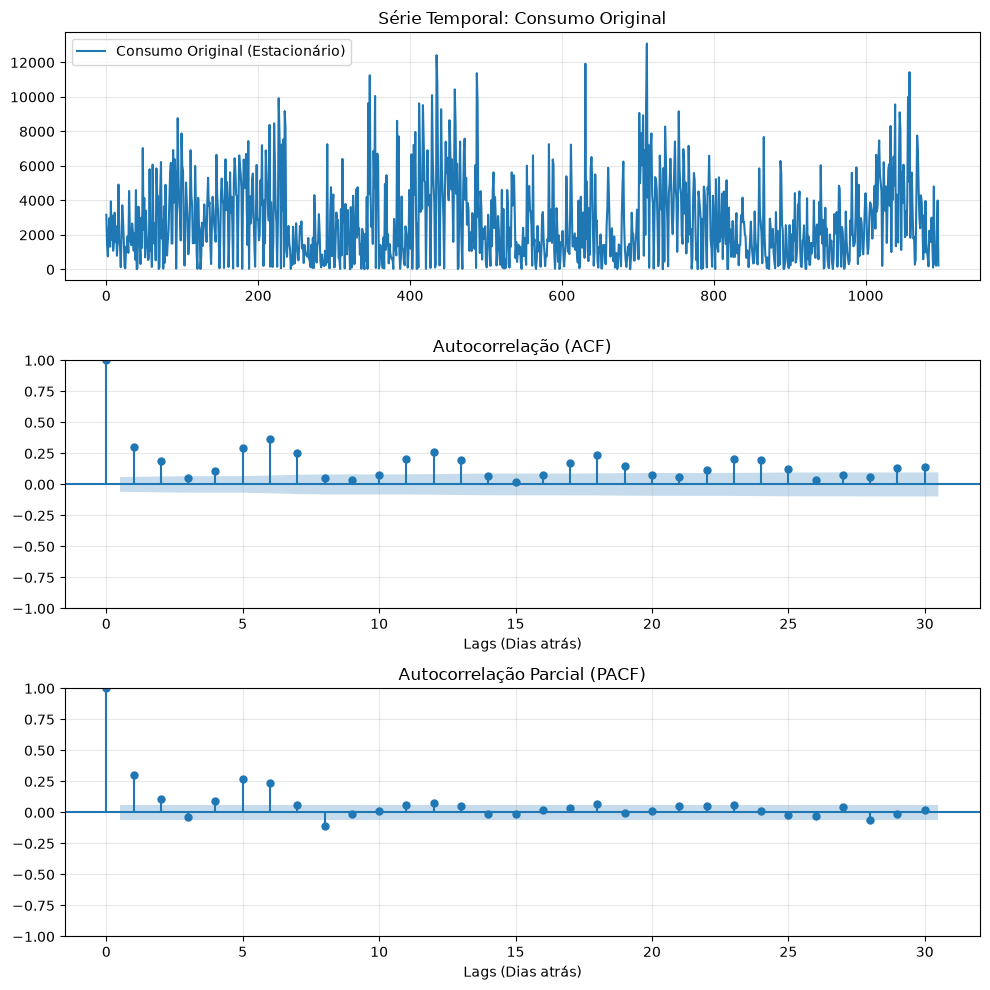

In [33]:
# Visualization of the original and differenced series, along with ACF and PACF plots
fig, axes = plt.subplots(3, 1, figsize=(10, 10))

# Consumption vs Diff
axes[0].plot(df_daily['daily_paper'], label='Consumo Original (Estacionário)', color='tab:blue')
axes[0].set_title('Série Temporal: Consumo Original', fontsize=12)
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# ACF of Differenced Series
plot_acf(df_daily['daily_paper'].dropna(), ax=axes[1], lags=30, alpha=0.05)
axes[1].set_title('Autocorrelação (ACF)', fontsize=12)
axes[1].set_xlabel('Lags (Dias atrás)')
axes[1].grid(True, alpha=0.3)

# PACF of Differenced Series
plot_pacf(df_daily['daily_paper'].dropna(), ax=axes[2], lags=30, alpha=0.05, method='ywm')
axes[2].set_title('Autocorrelação Parcial (PACF)', fontsize=12)
axes[2].set_xlabel('Lags (Dias atrás)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
# Analysis by month 
df_monthly = df_daily.set_index("date")["daily_paper"].resample("MS").sum().reset_index()
# ADF Test
adf_result = adfuller(df_monthly["daily_paper"].dropna())
p_value = adf_result[1]
print(f"Estatística ADF: {adf_result[0]:.4f}")
print(f"p-valor: {p_value:.6f}")

Estatística ADF: -1.5022
p-valor: 0.532429


C:\Users\9000639\AppData\Local\Temp\ipykernel_15976\2749128797.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df_monthly["daily_paper"].dropna())


In [35]:
# Due to ADF test results, we can conclude that the time series is non-stationary. Therefore, we will apply differencing to make it stationary.
df_monthly["daily_paper_diff"] = df_monthly["daily_paper"].diff()
# ADF Test
adf_result = adfuller(df_monthly["daily_paper_diff"].dropna())
p_value = adf_result[1]
print(f"Estatística ADF série diferenciada: {adf_result[0]:.4f}")
print(f"p-valor: {p_value:.6f}")

Estatística ADF série diferenciada: -7.0926
p-valor: 0.000000


C:\Users\9000639\AppData\Local\Temp\ipykernel_15976\362295779.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df_monthly["daily_paper_diff"].dropna())


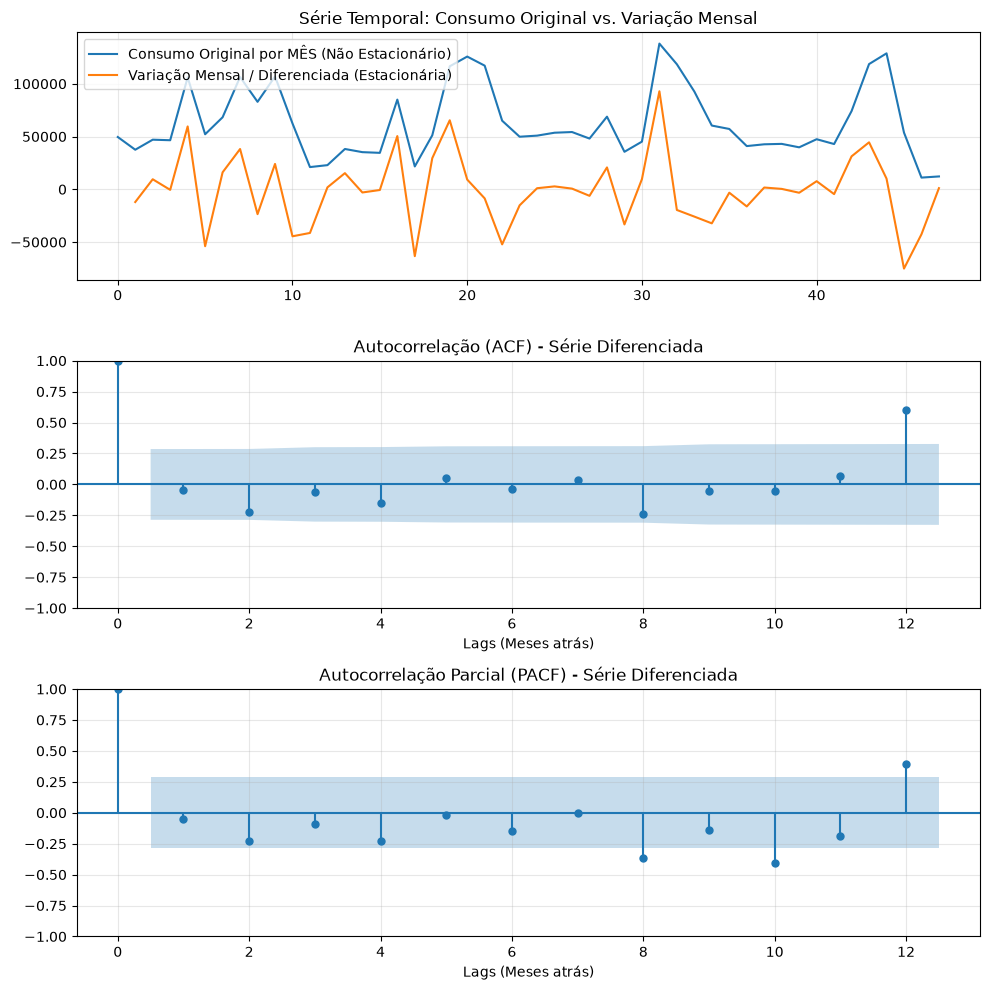

In [36]:
# Visualization of the original and differenced series, along with ACF and PACF plots
fig, axes = plt.subplots(3, 1, figsize=(10, 10))

# Consumption vs Diff
axes[0].plot(df_monthly['daily_paper'], label='Consumo Original por MÊS (Não Estacionário)', color='tab:blue')
axes[0].plot(df_monthly['daily_paper_diff'], label='Variação Mensal / Diferenciada (Estacionária)', color='tab:orange')
axes[0].set_title('Série Temporal: Consumo Original vs. Variação Mensal', fontsize=12)
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# ACF of Differenced Series
plot_acf(df_monthly['daily_paper_diff'].dropna(), ax=axes[1], lags=12, alpha=0.05)
axes[1].set_title('Autocorrelação (ACF) - Série Diferenciada', fontsize=12)
axes[1].set_xlabel('Lags (Meses atrás)')
axes[1].grid(True, alpha=0.3)

# PACF of Differenced Series
plot_pacf(df_monthly['daily_paper_diff'].dropna(), ax=axes[2], lags=12, alpha=0.05, method='ywm')
axes[2].set_title('Autocorrelação Parcial (PACF) - Série Diferenciada', fontsize=12)
axes[2].set_xlabel('Lags (Meses atrás)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
# Create new features based on the month and lagged values of the consumption
df_monthly = (
    df_daily.set_index("date")
      .resample("MS")
      .agg(
          consumption=("daily_paper", "sum"),
          daily_mean=("daily_paper", "mean"),
          daily_std=("daily_paper", "std"),
          daily_max=("daily_paper", "max"),
          daily_min=("daily_paper", "min"),
          daily_median=("daily_paper", "median"),
          days_observed=("daily_paper", "count")
      )
      .reset_index()
)

for lag in [1, 2, 3, 6, 12, 13]:
    df_monthly[f"consumption_lag_{lag}"] = df_monthly["consumption"].shift(lag)

for window in [3, 6, 12]:
    df_monthly[f"rolling_mean_{window}"] = df_monthly["consumption"].shift(1).rolling(window).mean()
    df_monthly[f"rolling_std_{window}"] = df_monthly["consumption"].shift(1).rolling(window).std()
    df_monthly[f"rolling_min_{window}"] = df_monthly["consumption"].shift(1).rolling(window).min()
    df_monthly[f"rolling_max_{window}"] = df_monthly["consumption"].shift(1).rolling(window).max()

df_monthly["change_1m"] = df_monthly["consumption"].shift(1) - df_monthly["consumption"].shift(2)
df_monthly["pct_change_1m"] = df_monthly["consumption"].pct_change().shift(1)
df_monthly["yoy_change"] = df_monthly["consumption"].shift(1) / df_monthly["consumption"].shift(13) - 1
df_monthly["month"] = df_monthly["date"].dt.month
df_monthly["quarter"] = df_monthly["date"].dt.quarter
df_monthly["year"] = df_monthly["date"].dt.year
df_monthly["days_in_month"] = df_monthly["date"].dt.days_in_month
df_monthly["month_sin"] = [sin(2*pi*month/12) for month in df_monthly["month"]]
df_monthly["month_cos"] = [cos(2*pi*month/12) for month in df_monthly["month"]]
df_monthly["trend"] = np.arange(len(df_monthly))
df_monthly["target"] = df_monthly["consumption"].shift(-1)
df_monthly


,date,consumption,daily_mean,daily_std,daily_max,daily_min,daily_median,days_observed,consumption_lag_1,consumption_lag_2,...,pct_change_1m,yoy_change,month,quarter,year,days_in_month,month_sin,month_cos,trend,target
0,2023-01-01,49560.0,2154.782609,1168.992999,4920.0,132.0,1728.0,23,NaN,NaN,...,NaN,NaN,1,1,2023,31,5.000000e-01,8.660254e-01,0,37500.0
1,2023-02-01,37500.0,1785.714286,1394.550865,4596.0,12.0,1596.0,21,49560.0,NaN,...,NaN,NaN,2,1,2023,28,8.660254e-01,5.000000e-01,1,47016.0
2,2023-03-01,47016.0,2350.800000,2000.852492,7032.0,144.0,1650.0,20,37500.0,49560.0,...,-0.243341,NaN,3,1,2023,31,1.000000e+00,6.123234e-17,2,46500.0
3,2023-04-01,46500.0,2583.333333,2080.851070,6228.0,24.0,2262.0,18,47016.0,37500.0,...,0.253760,NaN,4,2,2023,30,8.660254e-01,-5.000000e-01,3,106080.0
4,2023-05-01,106080.0,4080.000000,2287.667109,8772.0,48.0,3894.0,26,46500.0,47016.0,...,-0.010975,NaN,5,2,2023,31,5.000000e-01,-8.660254e-01,4,52152.0
5,2023-06-01,52152.0,2483.428571,1830.161211,6912.0,24.0,2316.0,21,106080.0,46500.0,...,1.281290,NaN,6,2,2023,30,1.224647e-16,-1.000000e+00,5,68256.0
6,2023-07-01,68256.0,2967.652174,1556.246259,6648.0,72.0,2760.0,23,52152.0,106080.0,...,-0.508371,NaN,7,3,2023,31,-5.000000e-01,-8.660254e-01,6,106428.0
7,2023-08-01,106428.0,3941.777778,1991.547781,6612.0,60.0,4212.0,27,68256.0,52152.0,...,0.308790,NaN,8,3,2023,31,-8.660254e-01,-5.000000e-01,7,82896.0
8,2023-09-01,82896.0,3454.000000,2112.416955,7440.0,36.0,3084.0,24,106428.0,68256.0,...,0.559248,NaN,9,3,2023,30,-1.000000e+00,-1.836970e-16,8,106932.0
9,2023-10-01,106932.0,4112.769231,2807.063552,9924.0,144.0,3642.0,26,82896.0,106428.0,...,-0.221107,NaN,10,4,2023,31,-8.660254e-01,5.000000e-01,9,62412.0


<Figure size 1800x800 with 0 Axes>

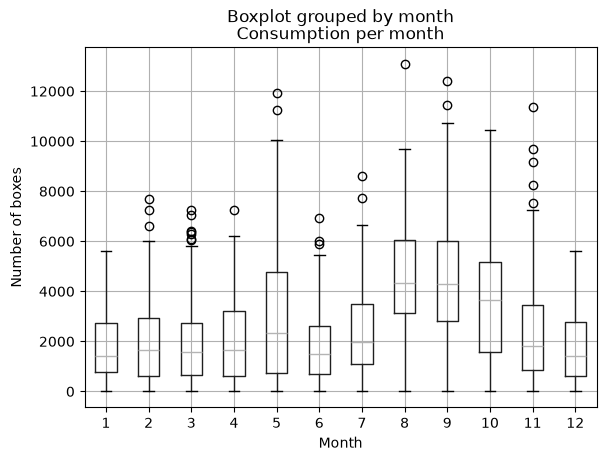

In [38]:
df_daily["month"] = df_daily["date"].dt.month
df_daily["year"] = df_daily["date"].dt.month
plt.figure(figsize=(18,8))
df_daily.boxplot(column="daily_paper", by="month", grid=False)
plt.title('Consumption per month')
plt.xlabel('Month')
plt.ylabel('Number of boxes')
plt.grid(True)
plt.show()

## Functions

In [39]:
def normalize_split_data(df, train_size=0.75, Target="target"):
    '''Normalizes the data and splits it into training and testing sets.
    Arguments:
    df -- DataFrame containing the data to be normalized and split
    train_size -- Proportion of the data to be used for training (default: 0.75)
    Target -- Name of the target column (default: "target")
    '''
    scaler = MinMaxScaler()
    train_data = df.iloc[:int(len(df)*train_size)]
    test_data = df.iloc[int(len(df)*train_size):]
    columns = df.drop(Target, axis=1).columns
    train_data[columns] = scaler.fit_transform(train_data.drop(Target, axis=1))
    test_data[columns] = scaler.transform(test_data.drop(Target, axis=1))

    return train_data, test_data, scaler

def train_model(X_train, y_train, X_test, y_test, model):
    '''Trains a model and returns the model, residuals, and metrics.
    Arguments:
    X_train -- Training features
    y_train -- Training target
    X_test -- Testing features
    y_test -- Testing target
    model -- Model to be trained
    '''
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mape = mean_absolute_percentage_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    results = pd.DataFrame({
        "MAE": [mae],
        "MAPE": [mape],
        "MSE": [mse],
        "R2": [r2]
    })
    residues = y_test.values.flatten() - predictions

    return model, residues, results


## Feature selection

In [40]:
# Preparing the data for modeling
df_proove = df_monthly.iloc[-4:]
df = df_monthly.iloc[:-4]
df = df_monthly.drop(columns="date").bfill()
df = df.sort_index()
train_size = int(len(df) * 0.75)
X_train = df.drop(columns="target").iloc[:train_size]
y_train = df["target"].iloc[:train_size]

# importance threshold
importance_threshold = 0.01

# Feature selection using Random Forest Regressor
rf = RandomForestRegressor(n_jobs=-1, random_state=65)
rf.fit(X_train, y_train)
df_rf_selected = pd.DataFrame({'Feature': X_train.columns, 'Importance': rf.feature_importances_}) # Feature importance from Random Forest
df_rf_selected = df_rf_selected.sort_values(by='Importance', ascending=False).reset_index(drop=True)
df_rf_selected['acumulative_importance'] = df_rf_selected['Importance'].cumsum()
et_features = df_rf_selected[df_rf_selected['Importance'] >= importance_threshold]['Feature'].tolist() # Select features that contribute to the specified importance threshold
#print(X_train.columns)
print(f"Selected features based on Random Forest importance threshold of {importance_threshold}:")
for feature in et_features:
    print(f"- {feature}")

Selected features based on Random Forest importance threshold of 0.01:
- month_sin
- daily_median
- rolling_mean_12
- pct_change_1m
- rolling_mean_6
- month_cos
- rolling_mean_3
- daily_mean
- consumption_lag_6
- daily_std
- change_1m
- rolling_std_6
- quarter
- month
- consumption_lag_2
- rolling_max_6
- consumption_lag_1
- rolling_std_3
- trend
- rolling_min_3
- days_observed
- days_in_month
- rolling_std_12
- daily_max
- rolling_max_3
- consumption


## Train Models

In [41]:
# Preparing data
df_base = df[et_features + ["target"]].dropna().reset_index(drop=True)
train, test, scaler = normalize_split_data(df=df_base)

# Training the XGBoost model
xgb_model, xgb_residues, xgb_results = train_model(
    train.drop("target", axis=1),
    train[["target"]],
    test.drop("target", axis=1),
    test[["target"]],
    XGBRegressor())

# Training the LightGBM model
lgbm_model, lgbm_residues, lgbm_results = train_model(
    train.drop("target", axis=1),
        train[["target"]],
        test.drop("target", axis=1),
        test[["target"]],
        LGBMRegressor())

# Training the Random Forest model
rf_model, rf_residues, rf_results = train_model(
    train.drop("target", axis=1),
        train[["target"]],
        test.drop("target", axis=1),
        test[["target"]],
        RandomForestRegressor())

# Training the Extra Trees model
et_model, et_residues, et_results = train_model(
    train.drop("target", axis=1),
        train[["target"]],
        test.drop("target", axis=1),
        test[["target"]],
        ExtraTreesRegressor())

# Training the CatBoost model
ctbm_model, ctbm_residues, ctbm_results = train_model(
    train.drop("target", axis=1),
        train[["target"]],
        test.drop("target", axis=1),
        test[["target"]],
        CatBoostRegressor())

# Aggregating the results of all models
results = pd.concat([xgb_results, lgbm_results, rf_results, et_results, ctbm_results], axis=0)
results.index = ["XGBoost", "LightGBM", "Random Forest", "Extra Trees", "CatBoost"]

[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 35, number of used features: 0
[LightGBM] [Info] Start training from score 66382.285714
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the 

c:\Users\9000639\Documents\CQ_SerieTemporal\temporal-series-analysis\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\9000639\Documents\CQ_SerieTemporal\temporal-series-analysis\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Learning rate set to 0.024107
0:	learn: 31855.5091001	total: 936us	remaining: 936ms
1:	learn: 31529.6445940	total: 1.82ms	remaining: 907ms
2:	learn: 31274.7553511	total: 2.89ms	remaining: 961ms
3:	learn: 30924.4974197	total: 3.82ms	remaining: 951ms
4:	learn: 30652.9024096	total: 4.71ms	remaining: 937ms
5:	learn: 30359.7641889	total: 5.48ms	remaining: 907ms
6:	learn: 30112.1098431	total: 6.22ms	remaining: 883ms
7:	learn: 29840.0198282	total: 6.92ms	remaining: 858ms
8:	learn: 29617.6135120	total: 7.63ms	remaining: 840ms
9:	learn: 29354.1318173	total: 8.59ms	remaining: 851ms
10:	learn: 29178.7485675	total: 9.36ms	remaining: 841ms
11:	learn: 28932.2826760	total: 10ms	remaining: 824ms
12:	learn: 28707.9834927	total: 10.8ms	remaining: 819ms
13:	learn: 28508.7648361	total: 11.4ms	remaining: 800ms
14:	learn: 28286.6707103	total: 12ms	remaining: 788ms
15:	learn: 28064.1675107	total: 12.6ms	remaining: 774ms
16:	learn: 27830.6482367	total: 13.3ms	remaining: 767ms
17:	learn: 27572.5075016	total: 1

In [42]:
results.sort_values(by="MSE", ascending=True)

,MAE,MAPE,MSE,R2
Extra Trees,18664.830000,0.847103,5.884439e+08,0.514792
XGBoost,17934.091797,0.857421,6.686950e+08,0.448620
Random Forest,23286.430000,0.985857,8.223569e+08,0.321917
CatBoost,24914.946863,0.995865,8.740419e+08,0.279299
LightGBM,32176.142857,1.168784,1.351236e+09,-0.114176


In [46]:
model = xgb_model
x_proove = df_proove[et_features]
y_proove = df_proove["target"]
x_scaled = scaler.transform(x_proove)
y_pred = model.predict(x_scaled)
df_proove["predicted"] = np.asarray(y_pred).reshape(-1)
df_proove

,date,consumption,daily_mean,daily_std,daily_max,daily_min,daily_median,days_observed,consumption_lag_1,consumption_lag_2,...,yoy_change,month,quarter,year,days_in_month,month_sin,month_cos,trend,target,predicted
44,2026-09-01,128808.0,4770.666667,2881.532925,11436.0,1128.0,4332.0,27,118656.0,74136.0,...,-0.140622,9,3,2026,30,-1.000000e+00,-1.836970e-16,44,53700.0,104721.640625
45,2026-10-01,53700.0,2983.333333,2121.935742,7764.0,276.0,2826.0,18,128808.0,118656.0,...,0.086987,10,4,2026,31,-8.660254e-01,5.000000e-01,45,11100.0,63034.105469
46,2026-11-01,11100.0,1387.500000,1013.575143,3000.0,108.0,1530.0,8,53700.0,128808.0,...,-0.420412,11,4,2026,30,-5.000000e-01,8.660254e-01,46,12192.0,50719.847656
47,2026-12-01,12192.0,1741.714286,1971.307325,4812.0,216.0,396.0,7,11100.0,53700.0,...,-0.816213,12,4,2026,31,-2.449294e-16,1.000000e+00,47,NaN,51578.546875
